In [7]:
import cv2
import time
from  ultralytics import YOLO
import torch
import matplotlib.pyplot as plt

In [2]:
# PYTORCH & CUDA INFORMATION
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

PyTorch version: 2.14.1+cu130
CUDA available: True


In [3]:
if torch.cuda.is_available():
    print(f"CUDA version: {torch.version.cuda}")
    print(f"Number of GPUs: {torch.cuda.device_count()}")

    for i in range(torch.cuda.device_count()):
        print(f"GPU {i}: {torch.cuda.get_device_name(i)}")
else:
    print("No CUDA GPU available to PyTorch.")

CUDA version: 13.0
Number of GPUs: 1
GPU 0: NVIDIA GeForce RTX 3060


In [4]:
# ULTRALYTICS YOLO DEVICE")
device = 0 if torch.cuda.is_available() else "cpu"
print(f"Selected device: {device}")

Selected device: 0


# TRAIN A DETECTION MODEL

In [5]:
# TRAINING MODEL
model = YOLO('/home/vuminhdangle/Documents/VuMinhDangLE/Realtime-Object-Counting/yolo11x.pt')

startTime = time.time()

model.train(
    data = '/home/vuminhdangle/Documents/VuMinhDangLE/Realtime-Object-Counting/dataset/data.yaml',
    batch = 0,
    epochs = 50,
    imgsz = (640, 640),
    name = 'apple_datasets_yolov11',
    save = True,
    patience = 20,
    save_period = -1,
    val = True
)

endTime = time.time()

New https://pypi.org/project/ultralytics/8.4.178 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.177 🚀 Python-3.10.12 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3060, 11910MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=0, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/vuminhdangle/Documents/VuMinhDangLE/Realtime-Object-Counting/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=(640, 640), iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, 

[W1017 10:57:20.391200009 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 79691776 bytes (free: 94306304, total: 12488343552).
[W1017 10:57:20.507459628 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 39845888 bytes (free: 35586048, total: 12488343552).
[W1017 10:57:20.507516674 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 39845888 bytes (free: 35586048, total: 12488343552).


AutoBatch: Using batch-size 3 for CUDA:0 5.92G/11.63G (51%) ✅
train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 6556.6±3216.6 MB/s, size: 107.0 KB)
train: Scanning /home/vuminhdangle/Documents/VuMinhDangLE/Realtime-Object-Counting/dataset/train/labels.cache... 500 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 500/500 174.8Mit/s 0.0s
albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5731.1±2146.9 MB/s, size: 110.2 KB)
val: Scanning /home/vuminhdangle/Documents/VuMinhDangLE/Realtime-Object-Counting/dataset/train/labels.cache... 500 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 500/500 139.8Mit/s 0.0s
optimizer: 'optimizer=auto' found, ignoring 'lr0=0.01' and determining best 'optimizer' and 'lr0' automatically... 
optimizer: AdamW(lr=0.002, momentum=0.9) with para

/home/vuminhdangle/Documents/VuMinhDangLE/Realtime-Object-Counting/.venv/lib/python3.10/site-packages/triton/backends/nvidia/driver.c:9:10: fatal error: Python.h: No such file or directory
    9 | #include <Python.h>
      |          ^~~~~~~~~~
compilation terminated.


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 84/84 7.7it/s 10.9s0.1s
                   all        500      25083      0.972      0.954      0.982      0.758
Speed: 0.2ms preprocess, 18.9ms inference, 0.1ms loss, 0.9ms postprocess per image
Results saved to /home/vuminhdangle/Documents/VuMinhDangLE/Realtime-Object-Counting/runs/detect/apple_datasets_yolov11


In [6]:
print(f"Training time: {(endTime - startTime)/60:.2f} minutes")

Training time: 30.85 minutes


# INFERENCE TESTING

In [8]:
model = YOLO('/home/vuminhdangle/Documents/VuMinhDangLE/Realtime-Object-Counting/runs/detect/apple_datasets_yolov11/weights/best.pt')

images_path = '/home/vuminhdangle/Documents/VuMinhDangLE/Realtime-Object-Counting/Video/frames/frame_839.png'


0: 384x640 53 Apples, 22.0ms
Speed: 0.9ms preprocess, 22.0ms inference, 0.9ms postprocess per image at shape (1, 3, 384, 640)


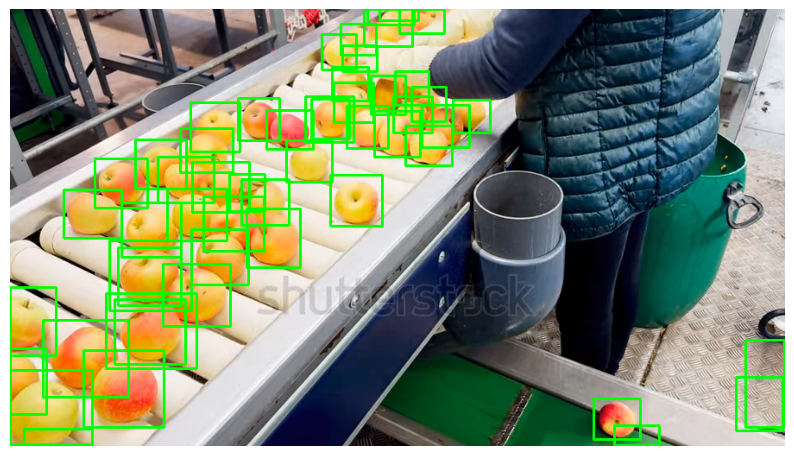

In [10]:
# fig, ax = plt.subplot(1,1,figsize=(15,16))
# ax = ax.ravel()

for i in range(1):
    # img_files = os.listdir(images_path)
    # img_file_name = random.choice(img_files)

    # img_path = os.path.join(images_path,img_file_name)
    img_path = images_path

    img = cv2.imread(img_path)
    results = model(img)[0]

    for box in results.boxes:
        x1, y1, x2, y2 = box.xyxy[0].cpu().numpy().astype(int)
        cv2.rectangle(img,(x1,y1),(x2,y2),(0,255,0),2)

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # ax[i].imshow(img)
    # ax[i].axis('off')
    plt.figure(figsize=(10,10))
    plt.imshow(img)
    plt.axis('off')
    plt.show()

# plt.show()